# Del dato solar a una descripción en lenguaje natural

**Escuela de Herramientas Computacionales en Astrofísica Solar 2026 · Sesión del 29 de octubre de 2026**
Juan Esteban Agudelo Ortiz · Observatorio Astronómico Nacional, Universidad Nacional de Colombia

En este cuaderno recorremos, con datos reales de SDO, el camino que sigue una observación solar para que un LLM la describa: **normalizar → elegir una región → convertirla en tokens → proyectarla al espacio del LLM → leer lo que el modelo escribe**. Es la base de un asistente de física solar que combina *Surya*, un foundation model de heliofísica, con un LLM abierto.

**Qué necesitas:** el entorno `escuela-solar` de la guía de instalación (Python, NumPy, Matplotlib, SciPy, pandas). **No hace falta GPU ni PyTorch**: Surya y el LLM ya se ejecutaron antes y aquí usamos sus resultados guardados en `../03_Datos`.

**Contenido**

- [0. Preparación](#seccion-0): librerías y archivos de datos
- [1. El dato: 13 canales de SDO](#seccion-1): con sus unidades y colormaps
- [2. Normalización de la entrada de Surya](#seccion-2): scaling, signed log y standardization
- [3. La región de interés](#seccion-3): de la caja de NOAA a coordenadas de tokens
- [4. Los tokens de Surya](#seccion-4): qué ve el modelo, token a token
- [5. Pooling: de 45 × 45 a 16 × 16 tokens](#seccion-5): 256 tokens para el LLM
- [6. El projector](#seccion-6): de 1280 a 4096 dimensiones
- [7. La secuencia que lee el LLM](#seccion-7): posiciones de imagen, prompt y caption; dónde hay loss
- [8. Resultados, con sus límites](#seccion-8): captions generados y baselines
- [9. Ejercicios](#seccion-9): cuatro ejercicios con `assert`

<a id="seccion-0" name="seccion-0"></a>

## 0. Preparación

In [1]:
import json
import re
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.patches import Rectangle
from scipy.special import erf

DATOS = Path("../03_Datos")
print("Archivos de datos:")
for archivo in sorted(DATOS.iterdir()):
    if archivo.name != ".gitkeep":
        print(f"  {archivo.name:45s} {archivo.stat().st_size / 1e6:6.1f} MB")

Archivos de datos:
  README.md                                        0.0 MB
  captions_ejemplo.json                            0.0 MB
  disco_completo_512.npz                           2.4 MB
  embeddings_ejemplo.npz                           6.1 MB
  normalizacion_constantes.json                    0.0 MB
  recorte_AR11944_20140107_1824.npz               22.2 MB
  resultados_heldout.json                          0.0 MB
  secuencia_ejemplo.json                           0.0 MB
  tokens_recorte_AR11944_20140107_1824.npy         5.2 MB


<a id="seccion-1" name="seccion-1"></a>

## 1. El dato: 13 canales de SDO

Surya recibe, para cada instante, **13 canales** del *Solar Dynamics Observatory* a resolución nativa (4096 × 4096 píxeles):

- **8 canales de AIA** (ultravioleta y ultravioleta extremo): 94, 131, 171, 193, 211, 304, 335 y 1600 Å. Cada longitud de onda ve plasma a una temperatura distinta.
- **5 productos de HMI**: el magnetograma de línea de visión (`hmi_m`), las tres componentes del campo vectorial (`hmi_bx`, `hmi_by`, `hmi_bz`) y la velocidad Doppler (`hmi_v`).

Además toma **dos instantes** separados 60 minutos. Cada observación es entonces un tensor de forma `(13, 2, 4096, 4096)`, unos 1.74 GB en 32 bits.

Para la clase usamos un recorte de 704 × 704 píxeles alrededor de la región activa NOAA 11944, el **7 de enero de 2014 a las 18:24 UT**, en pleno flare de clase X1.2.

In [2]:
recorte = np.load(DATOS / "recorte_AR11944_20140107_1824.npz")
canales = [str(c) for c in recorte["channels"]]
crudo = recorte["raw"]            # (13, 704, 704), valores sin normalizar
x0, y0, x1, y1 = recorte["bbox_px"]
print("canales:", canales)
print("forma del recorte:", crudo.shape, "| caja en píxeles de 4096 x 4096:", (x0, y0, x1, y1))

canales: ['aia94', 'aia131', 'aia171', 'aia193', 'aia211', 'aia304', 'aia335', 'aia1600', 'hmi_m', 'hmi_bx', 'hmi_by', 'hmi_bz', 'hmi_v']
forma del recorte: (13, 704, 704) | caja en píxeles de 4096 x 4096: (np.int64(1672), np.int64(1547), np.int64(2376), np.int64(2251))


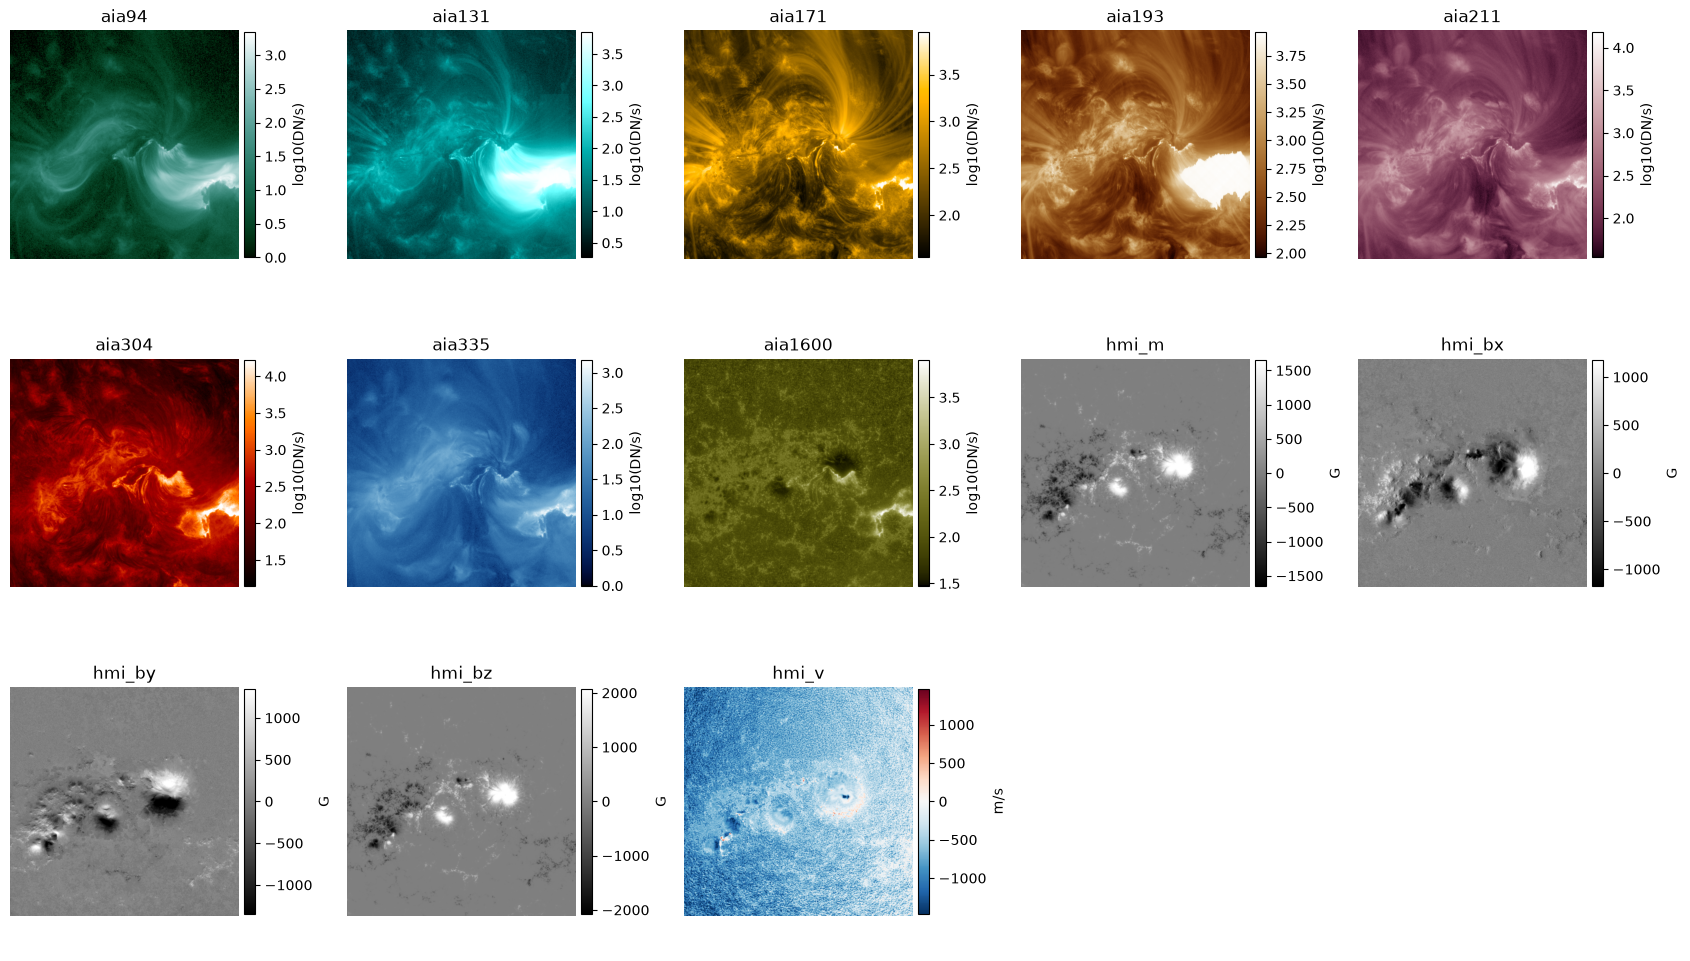

In [3]:
import sunpy.visualization.colormaps  # registra los mapas de color de SDO: "sdoaia171", ...

# Unidades tomadas de los atributos de los archivos de Surya
unidades = {n: "DN/s" for n in canales if n.startswith("aia")}
unidades.update({"hmi_m": "G", "hmi_bx": "G", "hmi_by": "G", "hmi_bz": "G", "hmi_v": "m/s"})

fig, ejes = plt.subplots(3, 5, figsize=(17, 10))
for ax, nombre, imagen in zip(ejes.ravel(), canales, crudo):
    if nombre.startswith("aia"):
        # escala logarítmica solo para mostrar; el mapa de color es el estándar de cada canal de AIA
        img = ax.imshow(np.log10(np.clip(imagen, 1, None)), origin="lower", cmap=f"sdo{nombre}")
        etiqueta = f"log10({unidades[nombre]})"
    else:
        limite = np.percentile(np.abs(imagen), 99.5)
        cmap = "RdBu_r" if nombre == "hmi_v" else "gray"
        img = ax.imshow(imagen, origin="lower", cmap=cmap, vmin=-limite, vmax=limite)
        etiqueta = unidades[nombre]
    ax.set_title(nombre)
    ax.axis("off")
    fig.colorbar(img, ax=ax, fraction=0.046, pad=0.02, label=etiqueta)
for ax in ejes.ravel()[len(canales):]:
    ax.axis("off")
plt.tight_layout()
plt.show()

Dos cosas para fijarse: los canales de AIA son positivos y los de HMI **tienen signo** (el magnetograma es positivo y negativo según la polaridad). En las imágenes de AIA usamos `log10` solo para *mostrarlas*; la normalización de Surya es otra, y es lo que sigue.

Cada canal de AIA se dibuja con el colormap estándar de su longitud de onda (el de `sunpy`) y cada barra de color indica la unidad. Los canales de AIA vienen en **DN/s** (cuentas por segundo; se muestra su `log10`), el campo magnético de HMI en **gauss (G)** (gris, simétrico alrededor de cero) y la velocidad Doppler `hmi_v` en **m/s** (azul-rojo, simétrica alrededor de cero).

<a id="seccion-2" name="seccion-2"></a>

## 2. Normalización de la entrada de Surya

Antes de que Surya vea una imagen, cada canal pasa por **tres pasos**, con constantes **globales del conjunto de datos** (no se calculan por imagen):

1. Multiplicar por un factor de escala (`sl_scale_factor`, 0.01 en los 13 canales).
2. **Signed log**: `sign(x) · log1p(|x|)`. Comprime los valores enormes (un flare) sin perder el signo, que HMI necesita.
3. **Standardization**: `(x − media) / (desviación + ε)`, con la media y la desviación del canal y `ε = 1e-8`.

Las constantes salen de un archivo que acompaña al modelo (`scalers.yaml`); aquí vienen en `normalizacion_constantes.json`.

In [4]:
datos_norm = json.loads((DATOS / "normalizacion_constantes.json").read_text())
constantes = datos_norm["constants"]
print("Instante:", datos_norm["instant"])
print("Constantes de aia94:", {k: v for k, v in constantes["aia94"].items() if not k.startswith("full_disk")})

Instante: 2014-01-07T18:24:00
Constantes de aia94: {'mean': 0.007682247087359428, 'std': 0.014216765761375427, 'epsilon': 9.99999993922529e-09, 'sl_scale_factor': 0.009999999776482582}


In [5]:
# Los tres pasos, a mano, sobre un canal del recorte.
nombre = "aia94"
k = constantes[nombre]
x = crudo[canales.index(nombre)].astype(np.float64)

paso1 = x * k["sl_scale_factor"]
paso2 = np.sign(paso1) * np.log1p(np.abs(paso1))
paso3 = (paso2 - k["mean"]) / (k["std"] + k["epsilon"])

for etiqueta, a in [("crudo", x), ("paso 1: x * 0.01", paso1), ("paso 2: signed log", paso2), ("paso 3: standardization", paso3)]:
    print(f"{etiqueta:24s} mín {a.min():10.3f}   máx {a.max():10.3f}   media {a.mean():8.3f}")

crudo                    mín      0.021   máx   2186.728   media   26.292
paso 1: x * 0.01         mín      0.000   máx     21.867   media    0.263
paso 2: signed log       mín      0.000   máx      3.130   media    0.139
paso 3: standardization  mín     -0.526   máx    219.601   media    9.203


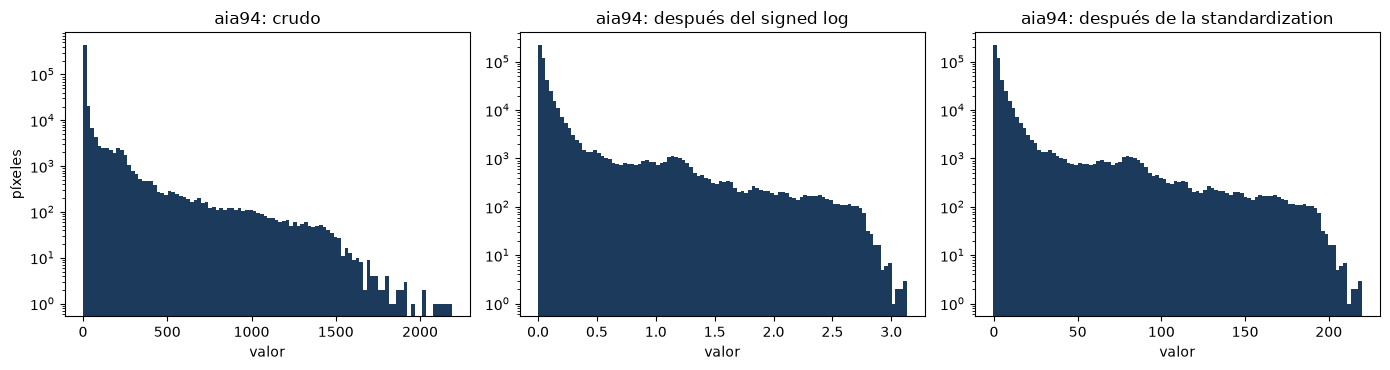

In [6]:
fig, ejes = plt.subplots(1, 3, figsize=(14, 3.8))
for ax, a, titulo in zip(ejes, [x, paso2, paso3], ["crudo", "después del signed log", "después de la standardization"]):
    ax.hist(a.ravel(), bins=100, color="#1b3a5c")
    ax.set_yscale("log")
    ax.set_title(f"{nombre}: {titulo}")
    ax.set_xlabel("valor")
ejes[0].set_ylabel("píxeles")
plt.tight_layout()
plt.show()

Ahora los 13 canales. La tabla usa la **imagen completa** (4096 × 4096) del mismo instante, no solo el recorte:

In [7]:
tabla = pd.DataFrame({
    "canal": datos_norm["channels"],
    "crudo mín": [constantes[c]["full_disk_raw"]["min"] for c in datos_norm["channels"]],
    "crudo máx": [constantes[c]["full_disk_raw"]["max"] for c in datos_norm["channels"]],
    "norm. mín": [constantes[c]["full_disk_normalized"]["min"] for c in datos_norm["channels"]],
    "norm. máx": [constantes[c]["full_disk_normalized"]["max"] for c in datos_norm["channels"]],
    "norm. media": [constantes[c]["full_disk_normalized"]["mean"] for c in datos_norm["channels"]],
    "norm. desv.": [constantes[c]["full_disk_normalized"]["std"] for c in datos_norm["channels"]],
}).set_index("canal").round(2)
tabla

,crudo mín,crudo máx,norm. mín,norm. máx,norm. media,norm. desv.
canal,,,,,,
aia94,0.00,2186.73,-0.54,219.60,0.58,5.07
aia131,0.00,7009.15,-0.71,76.63,0.50,3.31
aia171,0.00,8967.89,-1.21,7.55,0.10,1.10
aia193,0.00,9074.19,-1.22,6.72,0.36,1.19
aia211,0.00,15179.93,-0.89,13.91,0.46,1.31
aia304,0.00,16383.00,-1.00,19.99,0.16,1.37
aia335,0.00,1482.50,-0.65,59.15,0.30,1.65
aia1600,0.00,7900.40,-1.02,15.16,0.03,1.07
hmi_m,-1828.63,3283.80,-29.98,35.67,-0.02,1.70


**Qué se ve en la tabla**

- En los canales de AIA el valor crudo mínimo es 0, y un píxel en 0 **no termina en 0**: termina en `−media/desviación` (en `aia94`, unos −0.54).
- La salida de *una* imagen no queda con media 0 y desviación 1, porque las constantes son globales. Los píxeles de una región activa o de un flare quedan muchas desviaciones por encima de la media global: en `aia94` el máximo es ≈ 220.
- Los canales de HMI conservan el signo: `hmi_m` va de valores negativos a positivos después del signed log y la standardization.

<a id="seccion-3" name="seccion-3"></a>

## 3. La región de interés

El projector no recibe el disco completo, sino **los tokens de una región activa**. La caja de la región (en píxeles de la imagen de 4096 × 4096) sale de un catálogo: aquí, los reportes de NOAA SWPC consultados a través de HEK.

Surya convierte la imagen en una cuadrícula de **256 × 256 tokens**, uno por cada patch de 16 × 16 píxeles. Así que un píxel pasa a su token con una división entera por 16.

En los arreglos, las filas crecen hacia el norte, por eso mostramos las imágenes con `origin="lower"`.

In [8]:
disco = np.load(DATOS / "disco_completo_512.npz")
reduccion = int(disco["downsample"])      # el disco viene reducido 8 veces para ahorrar espacio

PARCHE = 16
tx0, ty0 = x0 // PARCHE, y0 // PARCHE
tx1, ty1 = -(-x1 // PARCHE), -(-y1 // PARCHE)   # división hacia arriba
print(f"caja en píxeles: x {x0}-{x1}, y {y0}-{y1}  ({x1 - x0} x {y1 - y0} px)")
print(f"caja en tokens:  x {tx0}-{tx1}, y {ty0}-{ty1}  -> recorte de {ty1 - ty0} x {tx1 - tx0} tokens de 256 x 256")

caja en píxeles: x 1672-2376, y 1547-2251  (704 x 704 px)
caja en tokens:  x 104-149, y 96-141  -> recorte de 45 x 45 tokens de 256 x 256


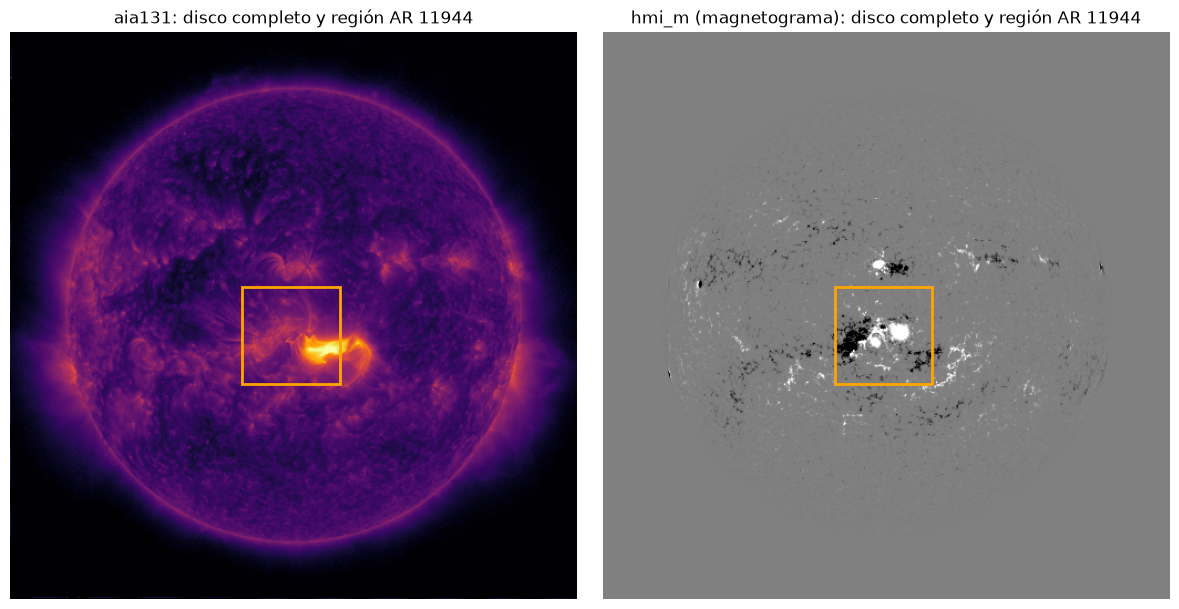

In [9]:
fig, ejes = plt.subplots(1, 2, figsize=(12, 6))
paneles = [("aia131", np.log10(np.clip(disco["aia131"], 1, None)), "inferno", None),
           ("hmi_m (magnetograma)", disco["hmi_m"], "gray", 300)]
for ax, (titulo, imagen, mapa, limite) in zip(ejes, paneles):
    if limite is None:
        ax.imshow(imagen, origin="lower", cmap=mapa)
    else:
        ax.imshow(imagen, origin="lower", cmap=mapa, vmin=-limite, vmax=limite)
    ax.add_patch(Rectangle((x0 / reduccion, y0 / reduccion), (x1 - x0) / reduccion, (y1 - y0) / reduccion,
                           fill=False, edgecolor="orange", linewidth=2))
    ax.set_title(f"{titulo}: disco completo y región AR 11944")
    ax.axis("off")
plt.tight_layout()
plt.show()

El flare desborda un poco la caja por el lado derecho: la caja viene del catálogo, no está ajustada al flare.

<a id="seccion-4" name="seccion-4"></a>

## 4. Los tokens de Surya

Corrimos Surya una sola vez sobre este instante: entra `(13, 2, 4096, 4096)` y sale `(65536, 1280)`, es decir, **65,536 tokens de 1280 números**, uno por patch. Aquí tienes los tokens de la región ya recortados, antes de cualquier reducción: `(45, 45, 1280)`.

Para ver algo en un token de 1280 números, calculamos su **norma** (la longitud del vector) y la dibujamos como imagen.

forma de los tokens del recorte: (45, 45, 1280) (alto, ancho, dimensión)


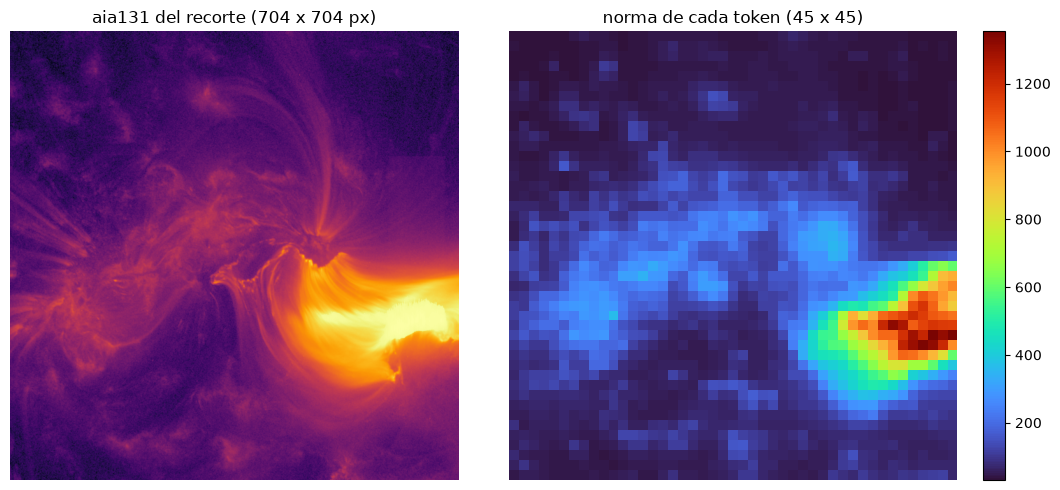

In [10]:
tokens = np.load(DATOS / "tokens_recorte_AR11944_20140107_1824.npy").astype(np.float32)
print("forma de los tokens del recorte:", tokens.shape, "(alto, ancho, dimensión)")
normas = np.linalg.norm(tokens, axis=-1)

fig, ejes = plt.subplots(1, 2, figsize=(11, 5))
ejes[0].imshow(np.log10(np.clip(crudo[canales.index("aia131")], 1, None)), origin="lower", cmap="inferno")
ejes[0].set_title("aia131 del recorte (704 x 704 px)")
im = ejes[1].imshow(normas, origin="lower", cmap="turbo")
ejes[1].set_title("norma de cada token (45 x 45)")
fig.colorbar(im, ax=ejes[1], fraction=0.046)
for ax in ejes:
    ax.axis("off")
plt.tight_layout()
plt.show()

**Para pensar:** ¿qué estructuras de la imagen se reflejan en el mapa de normas, y cuáles no? Cada token resume un patch de 16 × 16 píxeles de **los 13 canales y los dos instantes a la vez**, no solo del canal que estamos mirando.

<a id="seccion-5" name="seccion-5"></a>

## 5. Pooling: de 45 × 45 a 16 × 16 tokens

Un LLM no necesita (ni puede atender con comodidad) 2025 visual tokens por región. El costo del attention crece más que linealmente con la longitud de la secuencia. Reducimos el recorte a una cuadrícula fija de **16 × 16 = 256 tokens** promediando ventanas (*adaptive average pooling*), del mismo orden que el presupuesto de tokens que usa LLaVA-1.5 (576 en su caso).

Cada token de salida es el promedio de una ventana del recorte; las ventanas se solapan un poco cuando 45 no es múltiplo de 16.

In [11]:
def pooling_adaptativo(x, tam_salida=16):
    """Promedia ventanas de una cuadrícula de tokens hasta una cuadrícula fija.

    Args:
        x: Arreglo de forma (alto, ancho, dimensión).
        tam_salida: Lado de la cuadrícula de salida.

    Returns:
        Arreglo de forma (tam_salida, tam_salida, dimensión).
    """
    alto, ancho, dim = x.shape
    salida = np.empty((tam_salida, tam_salida, dim), dtype=np.float64)
    for i in range(tam_salida):
        f0, f1 = (i * alto) // tam_salida, -(-((i + 1) * alto) // tam_salida)
        for j in range(tam_salida):
            c0, c1 = (j * ancho) // tam_salida, -(-((j + 1) * ancho) // tam_salida)
            salida[i, j] = x[f0:f1, c0:c1].mean(axis=(0, 1))
    return salida


agrupados = pooling_adaptativo(tokens, 16)
print("antes:", tokens.shape, "-> después:", agrupados.shape, "-> como secuencia:", (16 * 16, agrupados.shape[-1]))

antes: (45, 45, 1280) -> después: (16, 16, 1280) -> como secuencia: (256, 1280)


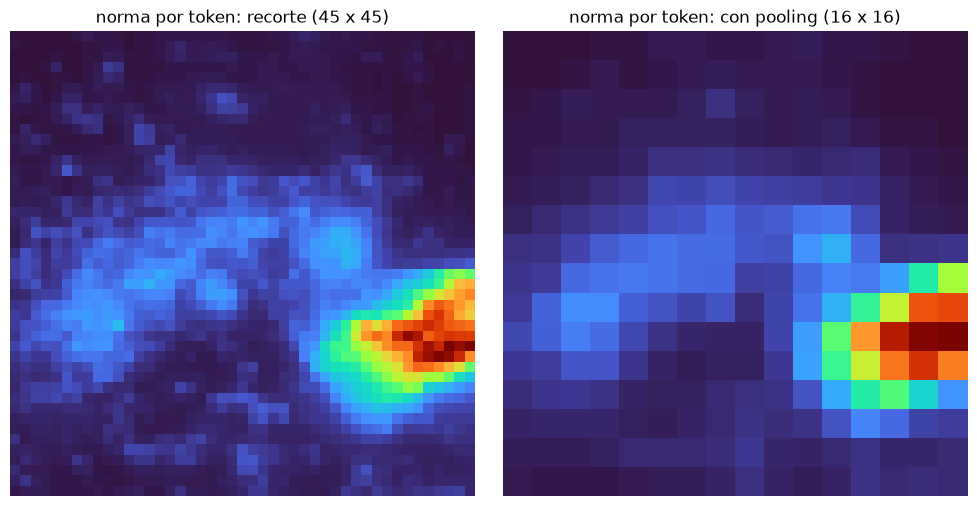

In [12]:
fig, ejes = plt.subplots(1, 2, figsize=(10, 5))
ejes[0].imshow(normas, origin="lower", cmap="turbo")
ejes[0].set_title("norma por token: recorte (45 x 45)")
ejes[1].imshow(np.linalg.norm(agrupados, axis=-1), origin="lower", cmap="turbo")
ejes[1].set_title("norma por token: con pooling (16 x 16)")
for ax in ejes:
    ax.axis("off")
plt.tight_layout()
plt.show()

*Nota de verificación (22 oct 2026):* esta función en NumPy da lo mismo que `torch.nn.functional.adaptive_avg_pool2d`, que es la que usamos al entrenar (diferencia máxima ≈ 6·10⁻⁸ en cinco tamaños de prueba). Se escribió en NumPy para que el notebook no necesite PyTorch.

<a id="seccion-6" name="seccion-6"></a>

## 6. El projector

Surya habla un "idioma" de vectores de 1280 números que no está alineado con el espacio de palabras del LLM, cuyos vectores tienen 4096 números. El **projector** es una pequeña red que traduce de uno al otro: un perceptrón multicapa con dos capas lineales y una no linealidad (GELU) en medio.

Es no lineal a propósito: Surya se hizo pretraining para *pronosticar* el Sol una hora adelante, no para alinearse con texto, así que no hay razón para suponer que una sola transformación lineal baste.

Es **lo único que se entrena**: Surya y el LLM quedan frozen.

In [13]:
def gelu(x):
    """GELU exacta, la misma que `torch.nn.GELU` por defecto."""
    return 0.5 * x * (1.0 + erf(x / np.sqrt(2.0)))


class Proyector:
    """MLP de dos capas: 1280 -> 4096 -> GELU -> 4096 (pesos aleatorios, solo para ver las formas)."""

    def __init__(self, dim_entrada=1280, dim_salida=4096, semilla=0):
        rng = np.random.default_rng(semilla)
        self.w1 = rng.normal(0, 0.02, (dim_entrada, dim_salida)); self.b1 = np.zeros(dim_salida)
        self.w2 = rng.normal(0, 0.02, (dim_salida, dim_salida)); self.b2 = np.zeros(dim_salida)

    def __call__(self, x):
        return gelu(x @ self.w1 + self.b1) @ self.w2 + self.b2

    def n_parametros(self):
        return sum(a.size for a in (self.w1, self.b1, self.w2, self.b2))


proyector = Proyector()
visuales = proyector(agrupados.reshape(256, 1280))
print("entrada:", (256, 1280), "-> salida:", visuales.shape)
print(f"parámetros entrenables: {proyector.n_parametros():,}  (≈ {proyector.n_parametros() / 1e6:.2f} M, frente a 366 M de Surya)")

entrada: (256, 1280) -> salida: (256, 4096)
parámetros entrenables: 22,028,288  (≈ 22.03 M, frente a 366 M de Surya)


Con pesos aleatorios la salida no significa nada. El entrenamiento ajusta estos ≈ 22 millones de parámetros para que los 256 vectores de salida, puestos delante del texto, ayuden al LLM a describir la región. Entrenamos el projector con 139 muestras (regiones activas en distintos instantes); el entrenamiento en sí corre en una GPU y no forma parte de esta sesión.

<a id="seccion-7" name="seccion-7"></a>

## 7. La secuencia que lee el LLM

El LLM no lee tensores de Surya, sino una **tabla de vectores, uno por posición**. La tabla contiene, de arriba abajo: el encabezado del chat, **256 posiciones reservadas para la imagen**, el prompt y la respuesta. En esas 256 posiciones se ponen los 256 vectores del projector; el resto son vectores de palabras normales.

El entrenamiento calcula la loss **solo sobre el caption** (y su token de fin), no sobre el prompt ni sobre la imagen.

Estos son los números reales de un ejemplo, tomados del archivo `secuencia_ejemplo.json`. El caption es la referencia de plantilla de una de las regiones held-out (AR 11892, 9 nov 2013), igual a las que se usan en el entrenamiento, y las posiciones salen del tokenizer real de Qwen3-8B:

In [14]:
secuencia = json.loads((DATOS / "secuencia_ejemplo.json").read_text())
caso = secuencia["cases"][0]
print("pregunta:", secuencia["prompt"])
print("caption :", caso["caption"], "\n")
print(f"posiciones en total: {caso['n_tokens']}")
print(f"  marca de inicio de imagen  : posición {caso['vision_start_index']}")
print(f"  posiciones de imagen       : {caso['vision_start_index'] + 1} a {caso['vision_end_index'] - 1}  ({caso['n_image_pad']} posiciones)")
print(f"  marca de fin de imagen     : posición {caso['vision_end_index']}")
print(f"  primera con loss           : posición {caso['first_supervised_index']}")
print(f"  posiciones con loss        : {caso['n_supervised']}  -> {caso['supervised_text']!r}")

pregunta: Describe this solar observation.
caption : An active region in the southern hemisphere on the east side of the disk (S05 E32) with 1 sunspot. It is a small single unipolar sunspot. 

posiciones en total: 316
  marca de inicio de imagen  : posición 3
  posiciones de imagen       : 4 a 259  (256 posiciones)
  marca de fin de imagen     : posición 260
  primera con loss           : posición 275
  posiciones con loss        : 40  -> 'An active region in the southern hemisphere on the east side of the disk (S05 E32) with 1 sunspot. It is a small single unipolar sunspot.<|im_end|>'


Las marcas como `<|im_end|>` o `<|image_pad|>` son **special tokens**: entradas reservadas del vocabulario del modelo que valen un solo número y marcan estructura (dónde acaba un turno, dónde va una imagen). No son texto normal.

Entre el prompt y el caption hay 14 posiciones sin loss: el fin del turno del usuario, el inicio del turno del asistente y un bloque `<think></think>` vacío. Qwen3 puede "pensar" antes de responder; aquí ese modo está apagado y el bloque vacío lo indica. La última posición (un salto de línea después de `<|im_end|>`) tampoco tiene loss.

<a id="seccion-8" name="seccion-8"></a>

## 8. Resultados, con sus límites

Con el projector ya entrenado, el modelo escribe un caption para regiones que **no vio** en el entrenamiento. Aquí van seis, junto a la referencia (que sale del catálogo NOAA con una plantilla fija, no de una persona ni de un LLM):

In [15]:
ejemplos = json.loads((DATOS / "captions_ejemplo.json").read_text())
for e in [e for e in ejemplos if e["split"] == "held_out"]:
    print(f"[{e['id']}]")
    print("  referencia:", e["reference"][:150])
    print("  generado  :", e["generated"][:150], "\n")

[20120307_0024_AR11430]
  referencia: An active region in the northern hemisphere near the central meridian (N19 E13) with 11 sunspots. It is a bipolar group with penumbra at both ends and
  generado  : An active region in the southern hemisphere on the west side of the disk (S11 W16) with 11 sunspots. It is a bipolar group with penumbra at both ends  

[20121109_1200_AR11609]
  referencia: An active region in the southern hemisphere on the east side of the disk (S15 E38) with 4 sunspots. It is a bipolar group where one spot has penumbra;
  generado  : An active region in the southern hemisphere on the east side of the disk (S17 E50) with 1 sunspot. It is a unipolar group with penumbra; its largest s 

[20131109_1200_AR11892]
  referencia: An active region in the southern hemisphere on the east side of the disk (S05 E32) with 1 sunspot. It is a small single unipolar sunspot.
  generado  : An active region in the southern hemisphere on the east side of the disk (S10 E10) with 1 sunspot.

Mirar ejemplos no basta: pueden elegirse a conveniencia. Medimos **sobre las 55 muestras held-out** (`resultados_heldout.json`) con una comparación automática y sin LLM, extrayendo del texto el hemisferio, la frase de posición y el número de manchas:

In [16]:
resultados = json.loads((DATOS / "resultados_heldout.json").read_text())

def hemisferio(texto):
    m = re.search(r"(northern|southern) hemisphere", texto)
    return m.group(1) if m else None

def posicion(texto):
    m = re.search(r"(near the central meridian|on the (?:west|east) side of the disk|close to the (?:west|east) limb)", texto)
    return m.group(1) if m else None

def manchas(texto):
    m = re.search(r"with (\d+) sunspot", texto)
    return int(m.group(1)) if m else None

def acierta(extraer, r):
    a, b = extraer(r["reference"]), extraer(r["generated"])
    return int(a is not None and a == b)

grupos = {"2 regiones del 7 ene 2014": [r for r in resultados if r["id"].startswith("20140107")],
          "4 días nuevos": [r for r in resultados if not r["id"].startswith("20140107")]}
filas = []
for nombre_grupo, filas_grupo in grupos.items():
    filas.append({"grupo": nombre_grupo, "n": len(filas_grupo),
                  "hemisferio": sum(acierta(hemisferio, r) for r in filas_grupo),
                  "posición": sum(acierta(posicion, r) for r in filas_grupo),
                  "manchas": sum(acierta(manchas, r) for r in filas_grupo)})
pd.DataFrame(filas).set_index("grupo")

,n,hemisferio,posición,manchas
grupo,,,,
2 regiones del 7 ene 2014,36,21,26,0
4 días nuevos,19,17,12,6


Un número suelto no dice si es bueno: hay que compararlo con un **baseline**, un modelo tonto que no mira la imagen. Estos son los baselines del run (siempre "norte", siempre "lado oeste", siempre "1 mancha", y predecir las coordenadas medias):

| Medida | 2 regiones del 7 ene (n = 36): modelo / baseline | 4 días nuevos (n = 19): modelo / baseline |
|---|---|---|
| Hemisferio correcto | 21 / **36** | **17** / 7 |
| Frase de posición correcta | **26** / 18 | **12** / 5 |
| Número de manchas correcto | 0 / 0 | 6 / 5 |
| Error de latitud (°) | 13.3 / **9.0** | **8.1** / 14.2 |
| Error de longitud (°) | **12.4** / 15.5 | **31.3** / 38.4 |

*Fuente: run 2 del prototipo (9 oct 2026). La columna "7 ene" son en la práctica solo 2 regiones observadas 18 veces; la mejor epoch se eligió con las mismas muestras held-out, así que los números son algo optimistas.*

**Lectura honesta**

- En los **días nuevos** el modelo supera a los baselines en hemisferio, posición y latitud: aprendió algo de **dónde** está la región en el disco.
- En las **2 regiones del 7 de enero** pierde contra "siempre norte" en hemisferio, porque ambas están en el norte. Los dos conjuntos se contradicen: las conclusiones dependen de qué regiones se aparten.
- **No aprendió** a contar manchas (6 de 19, apenas sobre el azar), y el error de longitud sigue siendo enorme (31° sobre un máximo de ±90°).
- Esto **no** demuestra que el modelo describa bien el Sol: demuestra que el pipeline entrena de punta a punta y que la imagen aporta información medible sobre la posición. Con 139 regiones de 18 días no se puede esperar más.

<a id="seccion-9" name="seccion-9"></a>

## 9. Ejercicios

Cada ejercicio tiene una celda con una comprobación (`assert`) que debe pasar cuando lo resuelvas.

**Ejercicio 1.** Normaliza `hmi_m` del recorte con los tres pasos y calcula el mínimo y el máximo. ¿Qué signo tiene cada uno y por qué el signed log conserva la polaridad?

In [17]:
# Ejercicio 1: completa las líneas.
k = constantes["hmi_m"]
x_m = crudo[canales.index("hmi_m")].astype(np.float64)
paso1_m = ...      # multiplica por el factor de escala
paso2_m = ...      # logaritmo con signo
paso3_m = ...      # estandariza

# assert paso3_m.min() < 0 < paso3_m.max()

**Ejercicio 2.** Cambia `tam_salida` en `pooling_adaptativo` a 8. ¿Qué forma tiene la salida y cuántos tokens verá el LLM? ¿Qué se pierde?

In [18]:
# Ejercicio 2
agrupados_8 = ...
# assert agrupados_8.shape == (8, 8, 1280)

**Ejercicio 3.** Una región activa de 512 × 512 píxeles, ¿cuántos tokens de Surya ocupa? ¿Y una de 704 × 704? Compruébalo con la fórmula de la sección 3.

In [19]:
# Ejercicio 3
tokens_512 = ...    # lado en tokens de una caja de 512 px
tokens_704 = ...    # lado en tokens de una caja de 704 px (cuidado con el redondeo hacia arriba cuando la caja no empieza en un múltiplo de 16)
# assert tokens_512 == 32

**Ejercicio 4.** En la sección 8 el modelo acierta el hemisferio en 21 de 36 muestras del 7 de enero, y "siempre norte" en 36 de 36. ¿Qué hace falta medir para saber si el modelo aprendió algo sobre el hemisferio? Propón una prueba y escríbela (pista: ¿acierta igual en las regiones del norte que en las del sur?).

---
*Los datos de este notebook son livianos y vienen precalculados. Para reproducirlos desde los archivos de Surya (GPU necesaria) y para ver el entrenamiento completo, consulta `05_Recursos_adicionales`.*